# Gabriele's Notebook

In this notebook i test several models

In [1]:
import pandas as pd
import numpy as np

# Plots
import matplotlib.pyplot as plt
import seaborn as sns
from plotly import graph_objects as go

# Utils
from tqdm.notebook import tqdm
from tabulate import tabulate

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import torch

# Custom modules
import Models_class as Models
import Dataset
import utils


# Set SEED
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## Data loading

We first load the dataframe from the parquet file.

In [2]:
df = pd.read_parquet('../Data/FI-2010-Cleaned/NoAuctionMinMax/SAMPO_NoAuction_MinMax.parquet')
df = df.head(20000)
df.drop(columns=['Label_20', 'Label_30', 'Label_50', 'Label_100', 'Day'], inplace=True)

target_cols = ['Label_10']
# Set target cols to dtype int
df[target_cols] = df[target_cols].astype(int)

df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Label_10
0,0.20256,0.178259,0.202397,0.022150,0.20256,0.171119,0.202397,0.008317,0.20247,0.276645,...,0.113201,0.200963,0.033407,0.202931,0.001737,0.200787,0.093404,0.202841,0.036892,1
1,0.20256,0.178259,0.202397,0.030483,0.20256,0.171119,0.202397,0.016650,0.20247,0.276645,...,0.113201,0.200963,0.033407,0.202931,0.001737,0.200787,0.093404,0.202841,0.036892,1
2,0.20256,0.178259,0.202397,0.022150,0.20256,0.171119,0.202397,0.008317,0.20247,0.276645,...,0.113201,0.200963,0.033407,0.202931,0.001737,0.200787,0.093404,0.202841,0.036892,1
3,0.20256,0.193322,0.202397,0.022150,0.20256,0.171119,0.202397,0.008317,0.20247,0.276645,...,0.113201,0.200963,0.033407,0.202931,0.001737,0.200787,0.093404,0.202841,0.036892,1
4,0.20256,0.193322,0.202397,0.022150,0.20256,0.171119,0.202397,0.008317,0.20247,0.276645,...,0.113201,0.200963,0.033407,0.202931,0.001737,0.200787,0.093404,0.202841,0.036892,1


In [23]:
# Split the dataframe into train and test
df_train, df_test = train_test_split(df, test_size=0.2, shuffle=False)
df_train, df_val = train_test_split(df_train, test_size=0.2, shuffle=False)

# Split covariates and response variable(s)
X_train, y_train = df_train.drop(columns=target_cols).values , df_train[target_cols].values
X_val, y_val     = df_val.drop(columns=target_cols).values   , df_val[target_cols].values
X_test, y_test   = df_test.drop(columns=target_cols).values  , df_test[target_cols].values

# Standardize the covariates
scaler_X = StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train = torch.tensor(X_train, dtype=torch.float32).to(device)
y_train = torch.tensor(y_train, dtype=torch.float32).to(device)
X_val = torch.tensor(X_val, dtype=torch.float32).to(device)
y_val = torch.tensor(y_val, dtype=torch.float32).to(device)
X_test = torch.tensor(X_test, dtype=torch.float32).to(device)
y_test = torch.tensor(y_test, dtype=torch.float32).to(device)

# Build TimeSeriesDataset
SEQ_LEN_X = 50
SEQ_LEN_Y = 1
OFFSET = 0
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = 'classification'
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = 'classification'
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = 'classification'
)

# Build TimeSeriesLoader
BATCH_SIZE = 16
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [24]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 12750 samples
Test dataset: 3950 samples


## Models

### Basic LSTM

In [5]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

The model has 81795 parameters


Training:   0%|          | 0/3 [00:00<?, ?it/s]

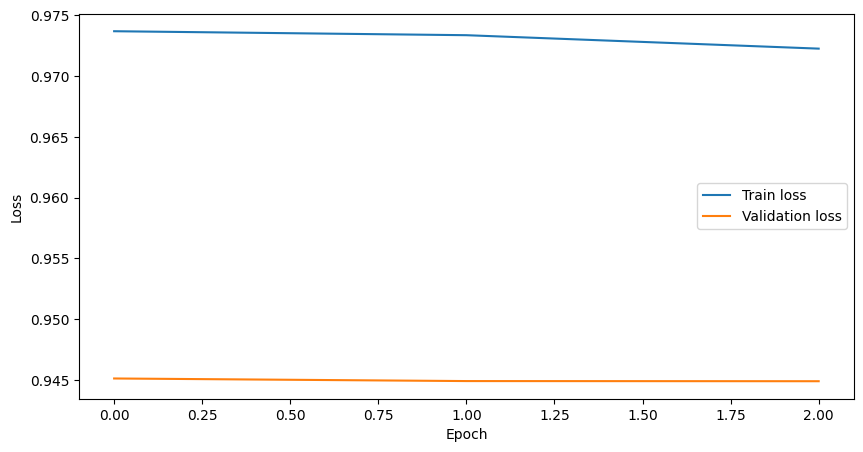

In [6]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = len(np.unique(y_train.cpu().numpy()))
HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.0
# Optimizer parameters
LEARNING_RATE = 1e-3

# Build the model
model = Models.LSTM(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    num_layers = NUM_LAYERS,
    dropout = DROPOUT
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.CrossEntropyLoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 3,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

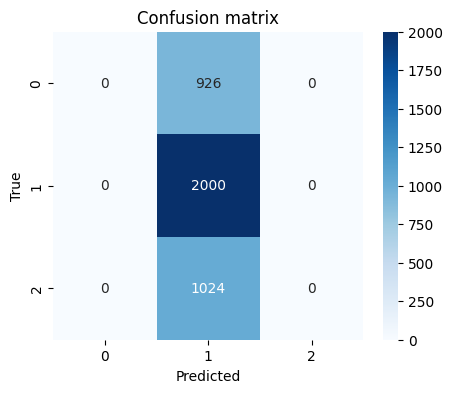

In [7]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)
pred = np.argmax(pred, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(true, pred.round())
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix')
plt.show()

In [8]:
# Classification report
from sklearn.metrics import classification_report

print(classification_report(true, pred, zero_division=0))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       926
           1       0.51      1.00      0.67      2000
           2       0.00      0.00      0.00      1024

    accuracy                           0.51      3950
   macro avg       0.17      0.33      0.22      3950
weighted avg       0.26      0.51      0.34      3950



### Aragosta

In [25]:
dataloader_train.dataset.channels = True
dataloader_val.dataset.channels = True
dataloader_test.dataset.channels = True

The model has 216323 parameters


Training:   0%|          | 0/20 [00:00<?, ?it/s]

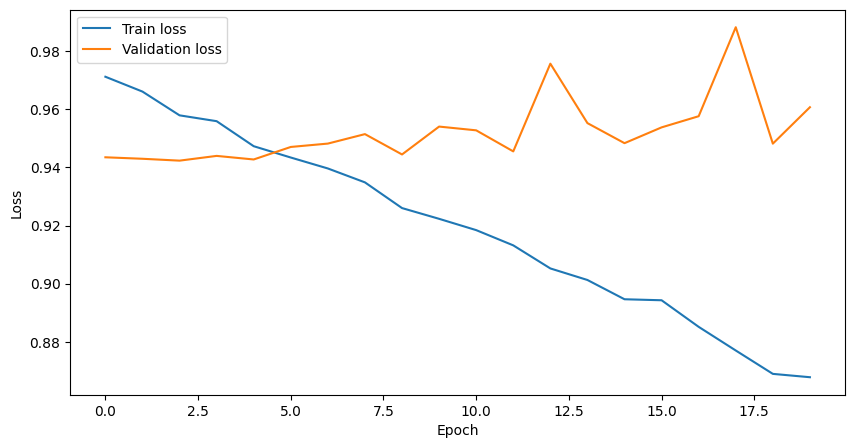

In [26]:
# Model parameters
INPUT_SIZE = X_train.shape[1]
OUTPUT_SIZE = len(np.unique(y_train.cpu().numpy()))
HIDDEN_SIZE = 64

# LSTM
LSTM_SIZE = 64
LSTM_LAYERS = 2

# CNN
CONV_CHANNELS = 64
INCEPTION_CHANNELS = 64

# Optimizer parameters
LEARNING_RATE = 1e-4
# Build the model
model = Models.Aragosta(
    input_size = INPUT_SIZE,
    output_size = OUTPUT_SIZE,
    hidden_size = HIDDEN_SIZE,
    lstm_size = LSTM_SIZE,
    lstm_layers = LSTM_LAYERS,
    conv_channels = CONV_CHANNELS,
    inception_channels = INCEPTION_CHANNELS,
).to(device)

# Print the number of parameters
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'The model has {n_params} parameters')

# Loss function
criterion = torch.nn.CrossEntropyLoss()
# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Train the model
train_res = utils.train(
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    model = model,
    optimizer = optimizer,
    criterion = criterion,
    device = device,
    n_epochs = 20,
)

# Plot loss evolution
plt.figure(figsize=(10, 5))
plt.plot(train_res['losses_train'], label='Train loss')
plt.plot(train_res['losses_val'], label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

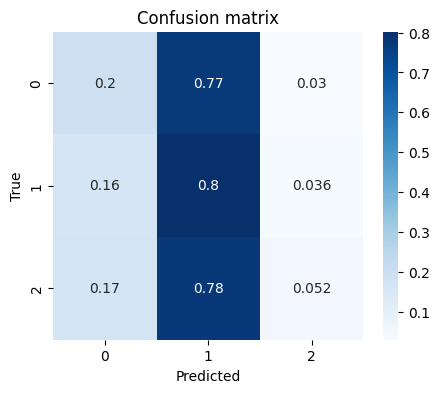

In [27]:
evaluation_res = utils.evaluate(
    model = model,
    loader = dataloader_test,
    criterion = criterion,
    device = device
)

true = np.concatenate(evaluation_res['true'], axis=0)
pred = np.concatenate(evaluation_res['pred'], axis=0)
pred = np.argmax(pred, axis=1)

# Confusion matrix
conf_matrix = confusion_matrix(true, pred.round(), normalize='true')
plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion matrix')
plt.show()

In [29]:
print(classification_report(true, pred, zero_division=0))

# AUC
from sklearn.metrics import roc_auc_score

y_pred = np.concatenate(evaluation_res['pred'], axis=0)
y_true = np.concatenate(evaluation_res['true'], axis=0)
roc_auc_score(y_true, y_pred, multi_class='ovo')
print(f'AUC: {roc_auc_score(y_true, y_pred, multi_class="ovo")}')

              precision    recall  f1-score   support

           0       0.27      0.20      0.23       926
           1       0.51      0.80      0.63      2000
           2       0.34      0.05      0.09      1024

    accuracy                           0.47      3950
   macro avg       0.38      0.35      0.31      3950
weighted avg       0.41      0.47      0.39      3950

AUC: 0.5211160745421616
